# Notebook 12 - Business Insights
Sprint 4 - EDA

The aim of this notebook is to move from visualization to observation to insight. A chart or a table is not an insight. An insight says what a pattern means for the business and what could be done about it.

Instead of writing: The graph shows churn by contract.

I write: Month-to-month customers are about half of the customer base but account for almost nine out of ten churners, so the contract type is the biggest lever for retention.

To keep the insights grounded in my own data, every section first calculates its numbers with code and prints them. I then read the printed numbers and write the insight from them, and I point out where the data cannot tell me the reason. Everything here is an association found in a snapshot of the data, and not proof of a cause.

**Dataset:** Telco Customer Churn (Kaggle, 7043 rows and 21 columns). Churn means the customer left in the last month.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# working copy for analysis only
d = df.copy()
d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce")
d["Churn_num"] = (d["Churn"] == "Yes").astype(int)

n_all = len(d)
n_churn = d["Churn_num"].sum()
monthly_all = d["MonthlyCharges"].sum()
monthly_churn = d.loc[d["Churn_num"] == 1, "MonthlyCharges"].sum()

print("Customers:", n_all, "| churned:", n_churn)

Customers: 7043 | churned: 1869


## 1. How big is the churn problem in money terms?

**Why this question:** A churn rate counts customers equally, but customers pay different amounts. The business cares about revenue, so I compare the share of customers lost with the share of monthly revenue lost.

In [2]:
share_customers = n_churn / n_all * 100
share_revenue = monthly_churn / monthly_all * 100

avg_churned = d.loc[d["Churn_num"] == 1, "MonthlyCharges"].mean()
avg_stayed = d.loc[d["Churn_num"] == 0, "MonthlyCharges"].mean()

print("Share of customers who churned:", round(share_customers, 1), "%")
print("Monthly revenue of churned customers:", round(monthly_churn), "out of", round(monthly_all))
print("Share of monthly revenue that churned:", round(share_revenue, 1), "%")
print()
print("Average monthly charge - churned:", round(avg_churned, 1), "| stayed:", round(avg_stayed, 1))
print("Yearly value of the churned monthly revenue:", round(monthly_churn * 12))

Share of customers who churned: 26.5 %
Monthly revenue of churned customers: 139131 out of 456117
Share of monthly revenue that churned: 30.5 %

Average monthly charge - churned: 74.4 | stayed: 61.3
Yearly value of the churned monthly revenue: 1669570


**Observation (from the numbers printed above):** The share of revenue that left is higher than the share of customers who left, and churned customers pay more on average per month than the ones who stayed.

**Insight:** The business is losing more money than the customer count suggests, because the customers who leave are paying above average. Churn is not only a loyalty problem, it is a revenue problem.

**Business impact and possible action:** The yearly value of the lost monthly revenue is the size of the prize for retention work. A retention budget can be compared with this number to decide how much is worth spending.

**ML relevance:** If a model is built, errors on high paying customers cost more, so a cost sensitive evaluation or a weighting by MonthlyCharges could be considered.

## 2. When in the customer life does churn happen?

**Why this question:** If churn is concentrated at one stage of the customer life, retention work can be aimed at that stage instead of being spread over all customers.

In [3]:
early = d["tenure"] <= 12

share_base_early = early.mean() * 100
share_churners_early = d.loc[early, "Churn_num"].sum() / n_churn * 100
rate_early = d.loc[early, "Churn_num"].mean() * 100
rate_later = d.loc[~early, "Churn_num"].mean() * 100

print("Customers in their first 12 months:", round(share_base_early, 1), "% of the base")
print("Churners who were in their first 12 months:", round(share_churners_early, 1), "% of all churners")
print("Churn rate in the first 12 months:", round(rate_early, 1), "%")
print("Churn rate after 12 months:", round(rate_later, 1), "%")

Customers in their first 12 months: 31.0 % of the base
Churners who were in their first 12 months: 55.5 % of all churners
Churn rate in the first 12 months: 47.4 %
Churn rate after 12 months: 17.1 %


**Observation (from the numbers printed above):** Customers in their first year are a minority of the base but a much bigger share of the churners, and their churn rate is several times higher than that of customers who stayed longer.

**Insight:** Churn is mainly an early life problem. The first year is the period in which the company decides whether a customer becomes a long term customer.

**Business impact and possible action:** An onboarding program, a check-in after the first month and the first bill, and a first year offer to move to a longer contract are natural actions. The data cannot say why new customers leave (price, service quality, a promotion that ended), so a customer survey or exit interview is needed.

**ML relevance:** Tenure is a strong feature. The relationship is not a straight line, so tenure groups or a tree based model can capture it.

## 3. Segment scorecard: which groups matter most?

**Why this question:** A segment is interesting when it is large, has a high churn rate, or holds a lot of revenue. A scorecard puts these facts for each segment side by side. The segments overlap (a customer can be in several), so the rows must not be added together.

In [4]:
protect = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
d["n_protect"] = (d[protect] == "Yes").sum(axis=1)

has_internet = d["InternetService"] != "No"
m2m = d["Contract"] == "Month-to-month"

segments = {
    "All customers": pd.Series(True, index=d.index),
    "Month-to-month contract": m2m,
    "One year contract": d["Contract"] == "One year",
    "Two year contract": d["Contract"] == "Two year",
    "Month-to-month + Fiber optic": m2m & (d["InternetService"] == "Fiber optic"),
    "Month-to-month + DSL": m2m & (d["InternetService"] == "DSL"),
    "Month-to-month + No internet": m2m & (d["InternetService"] == "No"),
    "Internet customers with no protective service": has_internet & (d["n_protect"] == 0),
    "Internet customers with 3 or 4 protective services": has_internet & (d["n_protect"] >= 3),
    "Electronic check payment": d["PaymentMethod"] == "Electronic check",
    "Senior citizens": d["SeniorCitizen"] == 1,
    "First 12 months": d["tenure"] <= 12,
    "Tenure above 48 months": d["tenure"] > 48,
}

rows = []
for name, mask in segments.items():
    sub = d[mask]
    churned = sub[sub["Churn_num"] == 1]
    rows.append([name, len(sub), round(len(sub) / n_all * 100, 1), round(sub["Churn_num"].mean() * 100, 1),
                 round(len(churned) / n_churn * 100, 1), round(sub["MonthlyCharges"].mean(), 1),
                 round(churned["MonthlyCharges"].sum())])

scorecard = pd.DataFrame(rows, columns=["segment", "customers", "pct_of_customers", "churn_rate_%",
                                        "pct_of_all_churners", "avg_monthly_charge", "monthly_revenue_lost"])
scorecard

,segment,customers,pct_of_customers,churn_rate_%,pct_of_all_churners,avg_monthly_charge,monthly_revenue_lost
0,All customers,7043,100.0,26.5,100.0,64.8,139131
1,Month-to-month contract,3875,55.0,42.7,88.6,66.4,120847
2,One year contract,1473,20.9,11.3,8.9,65.0,14118
3,Two year contract,1695,24.1,2.8,2.6,60.8,4165
4,Month-to-month + Fiber optic,2128,30.2,54.6,62.2,87.0,100482
5,Month-to-month + DSL,1223,17.4,32.2,21.1,50.2,18367
6,Month-to-month + No internet,524,7.4,18.9,5.3,20.4,1998
7,Internet customers with no protective service,1267,18.0,56.7,38.4,67.8,50806
8,Internet customers with 3 or 4 protective serv...,1411,20.0,10.1,7.6,85.5,13180
9,Electronic check payment,2365,33.6,45.3,57.3,76.3,84289


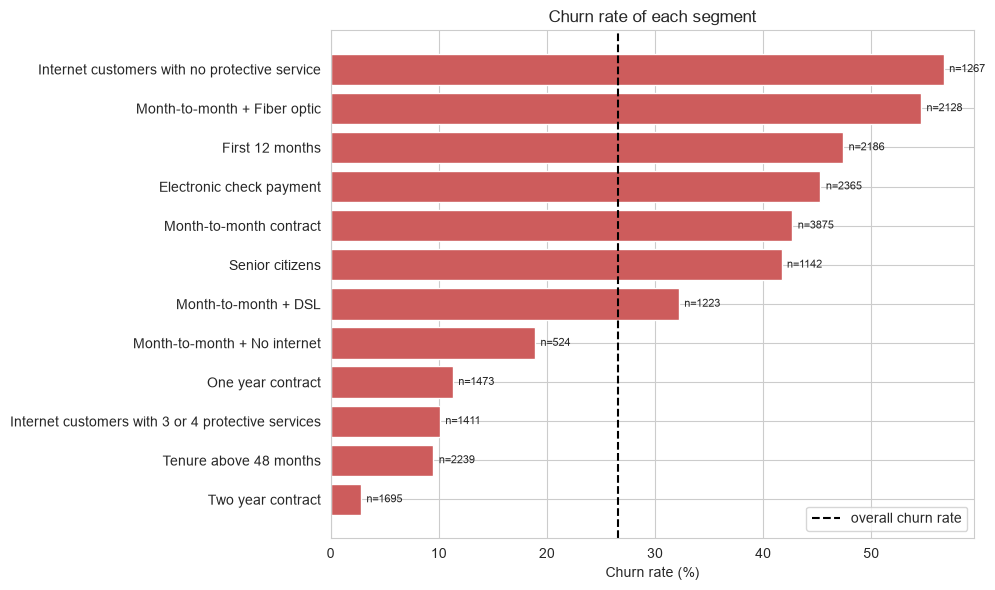

In [5]:
plot_data = scorecard[scorecard["segment"] != "All customers"].sort_values("churn_rate_%")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_data["segment"], plot_data["churn_rate_%"], color="indianred")
for i, (rate, n) in enumerate(zip(plot_data["churn_rate_%"], plot_data["customers"])):
    ax.text(rate + 0.5, i, "n=" + str(n), va="center", fontsize=8)
ax.axvline(n_churn / n_all * 100, color="black", linestyle="--", label="overall churn rate")
ax.set_xlabel("Churn rate (%)")
ax.set_title("Churn rate of each segment")
ax.legend()
plt.tight_layout()
plt.show()

**Observation (from the numbers printed above):** Month-to-month customers are about half of the base but make up most of the churners. The month-to-month fiber optic segment has the highest churn rate among the large segments and holds the biggest share of all churners and of the lost revenue. Two year contracts, customers with several protective services and customers with tenure above four years have very low churn rates.

**Insight:** The risk is concentrated. A small number of overlapping segments contain most of the churn, so a broad campaign for every customer would waste money, and a targeted one could work.

**Business impact and possible action:** The first priority segment is the new, month-to-month fiber optic customer. The second is the internet customer without any protective service. The segments with low churn are the stable revenue base to be protected.

**ML relevance:** These segments suggest features and interactions for the model (contract by internet service, protective services count, tenure bands), and a way to check later whether the model finds the same groups.

## 4. What could moving customers to longer contracts be worth?

**Why this question:** An insight becomes useful when it can be turned into a size of opportunity. I use a simple scenario with clear assumptions, and not a forecast. The assumption is that if some month-to-month customers behaved like one year customers, their churn rate would be lower. This is an upper bound, because customers who choose a longer contract may already be more loyal, so the contract may not be the only reason for the lower churn.

In [6]:
m2m_df = d[m2m]
rate_m2m = m2m_df["Churn_num"].mean()
rate_1y = d.loc[d["Contract"] == "One year", "Churn_num"].mean()
avg_loss = m2m_df.loc[m2m_df["Churn_num"] == 1, "MonthlyCharges"].mean()

print("Month-to-month churn rate:", round(rate_m2m * 100, 1), "%")
print("One year churn rate:", round(rate_1y * 100, 1), "%")
print("Average monthly charge of churned month-to-month customers:", round(avg_loss, 1))
print()

rows = []
for closed in [0.10, 0.25, 0.50]:
    saved = (rate_m2m - rate_1y) * len(m2m_df) * closed
    yearly = saved * avg_loss * 12
    rows.append([str(int(closed * 100)) + " % of the gap closed", round(saved), round(yearly)])

pd.DataFrame(rows, columns=["scenario", "customers_kept", "yearly_revenue_kept"])

Month-to-month churn rate: 42.7 %
One year churn rate: 11.3 %
Average monthly charge of churned month-to-month customers: 73.0



,scenario,customers_kept,yearly_revenue_kept
0,10 % of the gap closed,122,106752
1,25 % of the gap closed,305,266880
2,50 % of the gap closed,609,533760


**Observation (from the numbers printed above):** The gap between the month-to-month churn rate and the one year churn rate is large, so even closing a small part of it keeps hundreds of customers.

**Insight:** Even a modest success in moving customers to longer contracts has a clear money value. The table shows how the value grows with success, so the business can judge a campaign against its cost.

**Business impact and possible action:** A discount or a benefit for a one year contract can be compared with the yearly revenue kept in the table. The result should be tested with a small pilot, and not assumed, because the numbers are an upper bound.

**ML relevance:** This is an association and not a proven cause, which is a reminder that a predictive model for churn cannot say what would happen if a customer were moved to another contract.

## 5. The fiber optic puzzle

**Why this question:** Fiber optic customers pay the most and also churn the most. The reason matters. If they leave because of the price, the answer is a pricing action. If they leave for some other reason, a price cut would lose revenue without helping.

In [7]:
fiber = d.groupby("InternetService").agg(customers=("Churn_num", "count"),
                                         churn_rate=("Churn_num", "mean"),
                                         avg_charge=("MonthlyCharges", "mean"))
fiber["churn_rate"] = (fiber["churn_rate"] * 100).round(1)
fiber["avg_charge"] = fiber["avg_charge"].round(1)
print(fiber)
print()

print("Average monthly charge inside each service type, by churn:")
print(d.groupby(["InternetService", "Churn"])["MonthlyCharges"].mean().unstack().round(1))
print()

print("Churn rate (%) of fiber optic customers by contract:")
fiber_df = d[d["InternetService"] == "Fiber optic"]
print((fiber_df.groupby("Contract")["Churn_num"].mean() * 100).round(1))

                 customers  churn_rate  avg_charge
InternetService                                   
DSL                   2421        19.0        58.1
Fiber optic           3096        41.9        91.5
No                    1526         7.4        21.1

Average monthly charge inside each service type, by churn:
Churn              No   Yes
InternetService            
DSL              60.2  49.1
Fiber optic      93.9  88.1
No               21.1  20.4

Churn rate (%) of fiber optic customers by contract:
Contract
Month-to-month    54.6
One year          19.3
Two year           7.2
Name: Churn_num, dtype: float64


**Observation (from the numbers printed above):** Fiber optic customers have the highest average charge and the highest churn rate. Inside each service type, churned and not churned customers pay similar monthly amounts. Among fiber optic customers, the churn rate is much lower on longer contracts.

**Insight:** The price level alone does not separate churners from stayers inside the same service. The high churn of fiber optic customers is partly connected to the contract they hold, but a gap can remain even for long contracts. The data does not contain service quality, outages, competitor offers or complaints, so I cannot say whether the problem is quality, value for money or competition.

**Business impact and possible action:** Before any price change, the company should check service quality and customer complaints for fiber optic, compare with competitors in the areas where fiber is sold, and ask churned fiber customers why they left.

**ML relevance:** InternetService must stay in the model next to MonthlyCharges. A conclusion from the model about price should be avoided, because the price effect is mixed with the service effect.

## 6. Support and protection services

**Why this question:** Customers who have security, backup, device protection or tech support might be more attached to the company. If this is true, selling these services could be a retention tool. I restrict the analysis to customers with internet, because the customers without internet cannot buy these services.

In [8]:
internet = d[has_internet]
prot = internet.groupby("n_protect").agg(customers=("Churn_num", "count"), churn_rate=("Churn_num", "mean"))
prot["churn_rate"] = (prot["churn_rate"] * 100).round(1)
print(prot)
print()

none = internet[internet["n_protect"] == 0]
print("Internet customers with no protective service:", len(none), "(", round(len(none) / len(internet) * 100, 1), "% of internet customers )")
print("Of these, on month-to-month:", round((none["Contract"] == "Month-to-month").mean() * 100, 1), "%")

# is the effect still there inside month-to-month customers?
print()
print("Churn rate (%) inside month-to-month internet customers:")
inside = internet[internet["Contract"] == "Month-to-month"].groupby("n_protect")["Churn_num"].mean() * 100
print(inside.round(1))

           customers  churn_rate
n_protect                       
0               1267        56.7
1               1467        38.9
2               1372        23.8
3                941        12.4
4                470         5.3

Internet customers with no protective service: 1267 ( 23.0 % of internet customers )
Of these, on month-to-month: 94.9 %

Churn rate (%) inside month-to-month internet customers:
n_protect
0    58.5
1    45.2
2    36.5
3    22.9
4    26.5
Name: Churn_num, dtype: float64


**Observation (from the numbers printed above):** The churn rate falls as the number of protective services rises. A large group of internet customers has no protective service at all, and most of them are on month-to-month contracts. The same downward pattern is still visible when only month-to-month customers are compared.

**Insight:** The link between protective services and loyalty does not come only from the contract type, since it remains inside the month-to-month group. It is still an association: engaged customers may choose more services, and not the other way around.

**Business impact and possible action:** A free trial or a discounted bundle of tech support and online security for customers with none is an opportunity that can be tested with an experiment, with a control group, before it is rolled out.

**ML relevance:** The number of protective services can replace four overlapping columns with one feature, which reduces the multicollinearity found earlier.

## 7. Payment method

**Why this question:** Electronic check customers had the highest churn rate. I want to know if this is only because they are mostly month-to-month customers, or if payment method adds something.

In [9]:
d["auto_pay"] = d["PaymentMethod"].str.contains("automatic")

pay = d.groupby("PaymentMethod").agg(customers=("Churn_num", "count"), churn_rate=("Churn_num", "mean"))
pay["churn_rate"] = (pay["churn_rate"] * 100).round(1)
pay["share_month_to_month"] = (d.groupby("PaymentMethod")["Contract"].apply(lambda s: (s == "Month-to-month").mean()) * 100).round(1)
print(pay)
print()

print("Churn rate (%) inside month-to-month customers:")
print((d[m2m].groupby("PaymentMethod")["Churn_num"].mean() * 100).round(1))

                           customers  churn_rate  share_month_to_month
PaymentMethod                                                         
Bank transfer (automatic)       1544        16.7                  38.1
Credit card (automatic)         1522        15.2                  35.7
Electronic check                2365        45.3                  78.2
Mailed check                    1612        19.1                  55.4

Churn rate (%) inside month-to-month customers:
PaymentMethod
Bank transfer (automatic)    34.1
Credit card (automatic)      32.8
Electronic check             53.7
Mailed check                 31.6
Name: Churn_num, dtype: float64


**Observation (from the numbers printed above):** Electronic check users have the highest churn rate, and a bigger share of them are on month-to-month contracts than customers who pay in other ways. Inside the month-to-month group the electronic check users still churn more than the others, but the gap is smaller than in the whole data.

**Insight:** A part of the electronic check effect is the contract effect, and a part remains. Payment method is a useful second signal, but it is weaker than contract.

**Business impact and possible action:** Encouraging customers to move to automatic payment (a small discount or a reminder) can be tested as a retention action. Whether electronic check is a cause or only a sign of a less committed customer is not known.

**ML relevance:** Payment method should be kept as a feature, and its interaction with contract can be learned by a tree based model.

## 8. Customer profile: age group, family and gender

**Why this question:** Knowing which customer profiles are at higher risk helps to design offers. I also have to check which features should not be used for decisions about people.

In [10]:
for col in ["SeniorCitizen", "Partner", "Dependents", "gender"]:
    t = d.groupby(col).agg(customers=("Churn_num", "count"), churn_rate=("Churn_num", "mean"))
    t["churn_rate"] = (t["churn_rate"] * 100).round(1)
    print(col)
    print(t)
    print()

sc = d[d["SeniorCitizen"] == 1]
print("Senior citizens: share of customers", round(len(sc) / n_all * 100, 1), "%, share of churners",
      round(sc["Churn_num"].sum() / n_churn * 100, 1), "%")
print("Senior citizens with fiber optic:", round((sc["InternetService"] == "Fiber optic").mean() * 100, 1), "%",
      "| all customers with fiber optic:", round((d["InternetService"] == "Fiber optic").mean() * 100, 1), "%")

SeniorCitizen
               customers  churn_rate
SeniorCitizen                       
0                   5901        23.6
1                   1142        41.7

Partner
         customers  churn_rate
Partner                       
No            3641        33.0
Yes           3402        19.7

Dependents
            customers  churn_rate
Dependents                       
No               4933        31.3
Yes              2110        15.5

gender
        customers  churn_rate
gender                       
Female       3488        26.9
Male         3555        26.2

Senior citizens: share of customers 16.2 %, share of churners 25.5 %
Senior citizens with fiber optic: 72.8 % | all customers with fiber optic: 44.0 %


**Observation (from the numbers printed above):** Senior citizens have a clearly higher churn rate than the rest, although they are a small share of the base. Customers without a partner or without dependents churn more than those with them. Gender shows almost no difference. Senior citizens are more often on fiber optic than other customers, which may explain part of their higher churn.

**Insight:** Household and age information separate customers a little, and the difference for seniors can be partly explained by the type of service they use. Gender carries no useful signal.

**Business impact and possible action:** A support program for senior customers, such as simpler plans or assisted setup, can be considered, and the higher churn of fiber customers should be checked first. Age, gender and family status are sensitive attributes, so they should not be used to treat customers unfairly, for example by offering worse terms to some groups. Any model that uses them needs a fairness check.

**ML relevance:** Gender can be tested for removal, since it shows almost no relationship with the target. For the sensitive features, the team should decide whether to include them, after checking the legal and ethical side.

## 9. The stable revenue base

**Why this question:** Insights should include what is working and not only what is wrong. The loyal customers are the base of the business, and losing them would be expensive.

In [11]:
loyal = (d["Contract"] == "Two year") | (d["tenure"] > 48)

print("Customers on a two year contract or with tenure above 48 months:", loyal.sum(),
      "(", round(loyal.mean() * 100, 1), "% of customers )")
print("Their share of monthly revenue:", round(d.loc[loyal, "MonthlyCharges"].sum() / monthly_all * 100, 1), "%")
print("Their churn rate:", round(d.loc[loyal, "Churn_num"].mean() * 100, 1), "%")
print()

# upsell candidates: internet customers with no protective service who are NOT at high risk yet
nointernet = d[d["InternetService"] == "No"]
print("Customers without internet service:", len(nointernet), "(", round(len(nointernet) / n_all * 100, 1), "% )")
print("Their churn rate:", round(nointernet["Churn_num"].mean() * 100, 1), "%",
      "| average monthly charge:", round(nointernet["MonthlyCharges"].mean(), 1))

Customers on a two year contract or with tenure above 48 months: 2671 ( 37.9 % of customers )
Their share of monthly revenue: 40.0 %
Their churn rate: 8.2 %

Customers without internet service: 1526 ( 21.7 % )
Their churn rate: 7.4 % | average monthly charge: 21.1


**Observation (from the numbers printed above):** The loyal customers are a large share of the base and of the monthly revenue, and their churn rate is very low. The customers without internet service also churn very little, but they pay little per month.

**Insight:** The business has a stable base that brings a lot of revenue with little risk. The customers without internet are safe, but their value per customer is low, and they are an upsell opportunity only if the company wants to sell internet to them.

**Business impact and possible action:** Loyal customers deserve protection, with recognition programs and care not to disturb them with aggressive offers meant for risky segments. The no internet group can be a target for an internet upgrade offer, tested on a small group first.

**ML relevance:** The model will see few churners in the loyal segments, so it will find them easy. The harder and more valuable part of the problem is the customers in the middle, such as new month-to-month customers.

## 10. Anomalies and data limits found during the EDA

| Item | What I found | Why it matters |
|---|---|---|
| TotalCharges stored as text | 11 blank values, all for customers with tenure 0 | Needs a conversion and a decision, because these are new customers who were not yet billed |
| Tenure spike at 72 months | Many customers at the maximum of the range | Probably the limit of the observation window, so the loyalty of these customers is cut off |
| Tenure spike at 1 month | Many brand new customers | Shows heavy recent acquisition and the largest group of high risk customers |
| Add-on labels | No internet service is very different from No in the add-on columns | Merging them would hide a very low risk group |
| No univariate outliers | IQR and Z-score found none | No removal is needed, but TotalCharges is skewed |
| Overlapping features | TotalCharges is almost tenure times MonthlyCharges | A redundant feature that causes multicollinearity |
| Snapshot data | One row per customer at one moment | I cannot see how behavior changed over time, so reasons stay unknown |
| Churn definition | Left in the last month | The data does not say why, and it may not include customers who left before |

# 11. Insight Register

| No | Observation | Insight | Possible action | Confidence and caveat |
|---|---|---|---|---|
| 1 | Churned customers pay above average | Revenue lost is larger than the customer count suggests | Size retention budgets by revenue, not by customer count | High. Based on direct calculation |
| 2 | Most churn happens in the first year | The first year decides whether a customer stays | Onboarding and first year offers | High for the pattern, reasons unknown |
| 3 | Month-to-month customers give most of the churners | Contract type is the biggest lever | Incentives to move to one year contracts | Medium. Customers who choose long contracts may be loyal already |
| 4 | New month-to-month fiber customers are the top risk segment | Largest and riskiest segment | Targeted retention and service quality check | High for the size, reasons unknown |
| 5 | Fiber optic is expensive and churns the most, but price within a service looks similar for churners and stayers | The fiber problem is probably not price alone | Check quality, competition and complaints before changing prices | Medium. No quality data |
| 6 | More protective services go with lower churn | Engaged customers are more loyal | Test a free trial of tech support or security | Medium. Could be selection |
| 7 | Electronic check users churn more, partly because of contract | Payment method adds a smaller signal | Test an auto pay incentive | Medium |
| 8 | Seniors churn more, but are a small group and use fiber more often | A support program is possible, with care for fairness | Pilot support for seniors | Medium. Sensitive attribute |
| 9 | Loyal and two year customers bring a large share of revenue | The base is stable and valuable | Protect with loyalty care | High |

# Executive Summary

- The company loses about one customer in four, and a larger share of revenue, because churners pay above average.
- Churn is concentrated in the first year, among month-to-month customers, and especially among fiber optic customers.
- Customers on long contracts, with several protective services, or with a long tenure rarely leave.
- The best opportunities to test are moving month-to-month customers to longer contracts, offering protective services to internet customers with none, encouraging automatic payment, and investigating the fiber optic experience.
- The data shows associations in a snapshot. It cannot prove the reasons, so every action should first be tested with a pilot and a control group.


**What I learned:** A good insight states a pattern, says why it matters, and suggests an action, but it also says how sure I am and what the data cannot explain. Checking whether an effect remains inside a group (for example inside month-to-month customers) protects me from drawing a wrong conclusion from a mixed group.
